In [ ]:
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model='deepseek-v4-flash',
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(MessagesState):
    username: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "messages": [HumanMessage("你好，我是 " + state["username"])]
    }

def llm_node(state: OverAllState) -> OverAllState:
    res = model.invoke(state["messages"])

    return {
        "messages": [res],
        "output": res.content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "llm_node")
builder.add_edge("llm_node", END)

graph = builder.compile()
response = graph.invoke({"username": "小黄"})
print(response)

{'messages': [HumanMessage(content='你好，我是 小黄', additional_kwargs={}, response_metadata={}, id='5fa8c4a1-45db-429a-a89c-04921f1d2ad2'), AIMessage(content='你好呀，小黄！👋 很高兴认识你！有什么我可以帮你的吗？无论是学习、工作、生活上的问题，还是想聊聊天，我都在这儿呢～ 你名字里的“黄”是阳光的颜色，感觉你也是个充满活力的人呢！😄', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 58, 'prompt_tokens': 10, 'total_tokens': 68, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 10}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': '8ddd5d18-6501-4451-aeef-5eba4f746178', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a05a9a-d5ba-7d41-8523-82f8f170c715-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 58, 'total_tokens': 68, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}}

{'topic': '猫咪', 'poem': AIMessage(content='《戏题狸奴》\n独踞帘栊窥日影，时扑流萤过短墙。\n醉眠花荫浑无事，却向风前戏月光。\n\n赏析：这首作品以狸奴（猫）为主角，通过“独踞帘栊”、“时扑流萤”等生动细节，勾勒出猫咪慵懒而灵动的日常。后两句“醉眠花荫”、“戏月光”更以拟人手法赋予猫咪闲适自得的情态，整体意境轻盈活泼，充满生活意趣，展现了人与猫相伴的温馨画面。', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 120, 'prompt_tokens': 15, 'total_tokens': 135, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 15}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': '53390de8-a8e2-46b6-88ea-207b2500b67a', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a05ab3-a6a4-7812-854d-1b7b15b486f3-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 15, 'output_tokens': 120, 'total_tokens': 135, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}}), 'joke': AIMessage(content='“妈妈妈

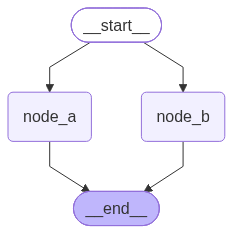

In [6]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    )
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    )
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪"})
print(res)

from IPython.display import display

display(graph)

======== 测试 1：正常工单处理 ========

[Node 1: 校验节点] 正在处理工单 TK-1001...
[Node 2: 分类节点] 正在分析文本意图...
[Node 3: 解决节点] 正在根据分类 [技术支持] 生成解决方案...

【最终工单处理单】:
工单ID: TK-1001
分类/优先级: 技术支持 / 中
处理结果: 建议您先尝试清除客户端缓存并重启应用。若仍无法解决，已自动为您转接二线技术专家。
审计日志历史:
  [10:30:56] [Validator] 文本校验通过
  [10:30:56] [Classifier] 识别分类为: [技术支持], 优先级: [中]
  [10:30:56] [Resolver] 成功自动生成解决方案


======== 测试 2：违规工单拦截 ========

[Node 1: 校验节点] 正在处理工单 TK-1002...
--> 检测到无效或非法工单，流转直接终止 (END)

【最终工单处理单】:
处理结果: 拒绝处理：包含违规敏感词汇
审计日志历史:
  [10:30:56] [Validator] 拦截敏感词: 刷单


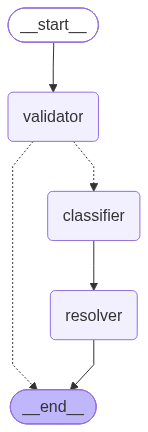

In [1]:
import time
from typing import List, Annotated, Literal
import operator
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END

# 1. 定义更丰富的工单状态 Schema
class TicketState(BaseModel):
    ticket_id: str                      # 工单ID
    raw_user_input: str                 # 用户原始输入
    is_valid: bool = True               # 输入是否合法
    category: str = "未分类"             # 工单类别：技术支持 / 财务退款 / 垃圾信息
    priority: str = "普通"               # 优先级：高 / 中 / 低
    resolution: str = ""                # 最终处理意见
    cur_id: str = "init"                # 当前处理节点
    logs: Annotated[List[str], operator.add] = []  # 全局流水审计日志

# 2. 节点 1：输入校验与敏感词过滤（模拟数据清洗逻辑）
def input_validator_node(state: TicketState) -> dict:
    print(f"\n[Node 1: 校验节点] 正在处理工单 {state.ticket_id}...")
    time.sleep(0.5) # 模拟业务耗时
    
    text = state.raw_user_input
    sensitive_words = ["炸弹", "刷单", "赌博"]
    
    # 模拟校验逻辑
    if not text.strip():
        return {
            "is_valid": False,
            "resolution": "拒绝处理：用户输入内容为空",
            "cur_id": "validator",
            "logs": [f"[{time.strftime('%H:%M:%S')}] [Validator] 校验失败：内容为空"]
        }
        
    for word in sensitive_words:
        if word in text:
            return {
                "is_valid": False,
                "resolution": "拒绝处理：包含违规敏感词汇",
                "cur_id": "validator",
                "logs": [f"[{time.strftime('%H:%M:%S')}] [Validator] 拦截敏感词: {word}"]
            }
            
    return {
        "is_valid": True,
        "cur_id": "validator",
        "logs": [f"[{time.strftime('%H:%M:%S')}] [Validator] 文本校验通过"]
    }

# 3. 节点 2：意图分类与优先级打标（模拟分类逻辑 / 调用分类模型）
def intent_classifier_node(state: TicketState) -> dict:
    print(f"[Node 2: 分类节点] 正在分析文本意图...")
    text = state.raw_user_input
    
    # 模拟规则分流/模型推理
    if "退款" in text or "扣费" in text:
        cat = "财务退款"
        prio = "高"
    elif "无法登录" in text or "报错" in text or "卡顿" in text:
        cat = "技术支持"
        prio = "中"
    else:
        cat = "综合咨询"
        prio = "低"
        
    return {
        "category": cat,
        "priority": prio,
        "cur_id": "classifier",
        "logs": [f"[{time.strftime('%H:%M:%S')}] [Classifier] 识别分类为: [{cat}], 优先级: [{prio}]"]
    }

# 4. 节点 3：自动生成解决方案（模拟业务逻辑/调用大模型生成回复）
def auto_resolver_node(state: TicketState) -> dict:
    print(f"[Node 3: 解决节点] 正在根据分类 [{state.category}] 生成解决方案...")
    
    # 模拟针对不同分类的自动处理流程
    if state.category == "财务退款":
        solution = "已为您触发系统预审，退款申请已提交至财务后台，预计1个工作日内到账。"
    elif state.category == "技术支持":
        solution = "建议您先尝试清除客户端缓存并重启应用。若仍无法解决，已自动为您转接二线技术专家。"
    else:
        solution = "感谢您的反馈，常见问题可参考帮助中心文档：https://docs.example.com"
        
    return {
        "resolution": solution,
        "cur_id": "resolver",
        "logs": [f"[{time.strftime('%H:%M:%S')}] [Resolver] 成功自动生成解决方案"]
    }

# 5. 条件路由函数：根据校验结果决定是否直接终止流程
def route_after_validation(state: TicketState) -> Literal["classifier", "__end__"]:
    if not state.is_valid:
        print("--> 检测到无效或非法工单，流转直接终止 (END)")
        return END
    return "classifier"

# 6. 构建图结构
builder = StateGraph(TicketState)

builder.add_node("validator", input_validator_node)
builder.add_node("classifier", intent_classifier_node)
builder.add_node("resolver", auto_resolver_node)

# 设置流程边
builder.add_edge(START, "validator")

# 条件边：Validator 处理完后，根据校验结果判断走 Classifier 还是直接 END
builder.add_conditional_edges(
    "validator",
    route_after_validation,
    {
        "classifier": "classifier",
        END: END
    }
)

builder.add_edge("classifier", "resolver")
builder.add_edge("resolver", END)

app = builder.compile()

# ================= 运行测试 =================
if __name__ == "__main__":
    # 运行用例 1：正常的技术支持工单
    print("======== 测试 1：正常工单处理 ========")
    input_1 = {
        "ticket_id": "TK-1001",
        "raw_user_input": "我的App今天一直卡顿，报错500无法登录！"
    }
    result_1 = app.invoke(input_1)
    print("\n【最终工单处理单】:")
    print(f"工单ID: {result_1['ticket_id']}")
    print(f"分类/优先级: {result_1['category']} / {result_1['priority']}")
    print(f"处理结果: {result_1['resolution']}")
    print("审计日志历史:")
    for log in result_1["logs"]:
        print(" ", log)

    print("\n" + "="*40 + "\n")

    # 运行用例 2：包含非法违规词的工单（测试条件分支拦截）
    print("======== 测试 2：违规工单拦截 ========")
    input_2 = {
        "ticket_id": "TK-1002",
        "raw_user_input": "加我QQ拉你进群一起刷单赚钱"
    }
    result_2 = app.invoke(input_2)
    print("\n【最终工单处理单】:")
    print(f"处理结果: {result_2['resolution']}")
    print("审计日志历史:")
    for log in result_2["logs"]:
        print(" ", log)
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))
display(builder)

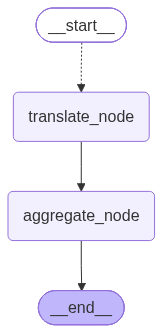

所有翻译任务完成！共收到 3 个结果。

最终生成的翻译列表：
 - [中文] Hello World (已翻译)
 - [日语] Hello World (已翻译)
 - [法语] Hello World (已翻译)


In [2]:
import operator
from typing import List, Annotated
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

# 1. 全局图状态 (Map-Reduce 最终汇总的状态)
class OverallState(BaseModel):
    text: str
    target_languages: List[str]
    # operator.add 负责把各个并行分支返回的列表项合并累加
    translations: Annotated[List[str], operator.add] = []

# 2. 单个分支节点的独立状态 (Map 节点的入参)
class TaskState(BaseModel):
    text: str
    language: str

# 3. 动态拆分路由函数 (Dynamic Fan-out 核心)
def map_languages(state: OverallState):
    """
    运行时根据 state.target_languages 的数量，
    动态创建 N 个并发任务发往 'translate_node'
    """
    return [
        Send("translate_node", TaskState(text=state.text, language=lang))
        for lang in state.target_languages
    ]

# 4. 并发执行的具体节点 (Map Task)
def translate_node(state: TaskState) -> dict:
    # 模拟翻译处理
    result = f"[{state.language}] {state.text} (已翻译)"
    return {"translations": [result]}

# 5. 汇总节点 (Reduce)
def aggregate_node(state: OverallState) -> dict:
    print(f"所有翻译任务完成！共收到 {len(state.translations)} 个结果。")
    return {}

# 6. 构建图结构
builder = StateGraph(OverallState)

builder.add_node("translate_node", translate_node)
builder.add_node("aggregate_node", aggregate_node)

# 从 START 出发，使用条件边动态扇出（Fan-out）到 translate_node
builder.add_conditional_edges(START, map_languages, ["translate_node"])

# 所有的 translate_node 执行完后自动汇聚到 aggregate_node
builder.add_edge("translate_node", "aggregate_node")
builder.add_edge("aggregate_node", END)

app = builder.compile()
from IPython.display import Image, display

# 渲染并展示架构图
display(Image(app.get_graph().draw_mermaid_png()))
# ================= 测试运行 =================
if __name__ == "__main__":
    # 运行时动态指定 3 个语言分支
    input_data = {
        "text": "Hello World",
        "target_languages": ["中文", "日语", "法语"]
    }
    
    result = app.invoke(input_data)
    
    print("\n最终生成的翻译列表：")
    for trans in result["translations"]:
        print(" -", trans)

======== 测试 1：正常工单处理 ========

[Node 1: 校验节点] 正在处理工单 TK-1001...
[Node 2: 分类节点] 正在分析文本意图...
[Node 3: 解决节点] 正在根据分类 [技术支持] 生成解决方案...

【最终工单处理单】:
工单ID: TK-1001
分类/优先级: 技术支持 / 中
处理结果: 建议您先尝试清除客户端缓存并重启应用。若仍无法解决，已自动为您转接二线技术专家。
审计日志历史:
  [12:16:46] [Validator] 文本校验通过
  [12:16:46] [Classifier] 识别分类为: [技术支持], 优先级: [中]
  [12:16:46] [Resolver] 成功自动生成解决方案


======== 测试 2：违规工单拦截 ========

[Node 1: 校验节点] 正在处理工单 TK-1002...

【最终工单处理单】:
处理结果: 拒绝处理：包含违规敏感词汇
审计日志历史:
  [12:16:46] [Validator] 拦截敏感词: 刷单


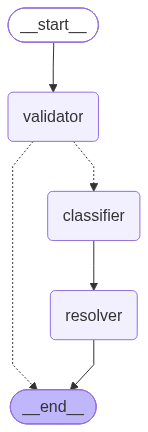

In [5]:
import time
from typing import List, Annotated
import operator
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command  # 1. 引入 Command 模块

# 1. 定义工单状态 Schema
class TicketState(BaseModel):
    ticket_id: str                      # 工单ID
    raw_user_input: str                 # 用户原始输入
    is_valid: bool = True               # 输入是否合法
    category: str = "未分类"             # 工单类别：技术支持 / 财务退款 / 垃圾信息
    priority: str = "普通"               # 优先级：高 / 中 / 低
    resolution: str = ""                # 最终处理意见
    cur_id: str = "init"                # 当前处理节点
    logs: Annotated[List[str], operator.add] = []  # 全局流水审计日志

# 2. 节点 1：用 Command 改写校验节点（不再依赖外部条件边）

def input_validator_node(state: TicketState) -> Command:
    print(f"\n[Node 1: 校验节点] 正在处理工单 {state.ticket_id}...")
    time.sleep(0.5)
    
    text = state.raw_user_input
    sensitive_words = ["炸弹", "刷单", "赌博"]
    
    # 情况 A: 输入为空 -> 拦截并直接跳转到 END
    if not text.strip():
        return Command(
            update={
                "is_valid": False,
                "resolution": "拒绝处理：用户输入内容为空",
                "cur_id": "validator",
                "logs": [f"[{time.strftime('%H:%M:%S')}] [Validator] 校验失败：内容为空"]
            },
            goto=END  # 直接控制跳转到结束
        )
        
    # 情况 B: 包含违规词 -> 拦截并直接跳转到 END
    for word in sensitive_words:
        if word in text:
            return Command(
                update={
                    "is_valid": False,
                    "resolution": "拒绝处理：包含违规敏感词汇",
                    "cur_id": "validator",
                    "logs": [f"[{time.strftime('%H:%M:%S')}] [Validator] 拦截敏感词: {word}"]
                },
                goto=END  # 直接控制跳转到结束
            )
            
    # 情况 C: 校验通过 -> 正常跳转到 classifier 节点
    return Command(
        update={
            "is_valid": True,
            "cur_id": "validator",
            "logs": [f"[{time.strftime('%H:%M:%S')}] [Validator] 文本校验通过"]
        },
        goto="classifier"  # 动态控制流跳转到下一个节点
    )

# 3. 节点 2：意图分类与优先级打标
def intent_classifier_node(state: TicketState) -> dict:
    print(f"[Node 2: 分类节点] 正在分析文本意图...")
    text = state.raw_user_input
    
    if "退款" in text or "扣费" in text:
        cat = "财务退款"
        prio = "高"
    elif "无法登录" in text or "报错" in text or "卡顿" in text:
        cat = "技术支持"
        prio = "中"
    else:
        cat = "综合咨询"
        prio = "低"
        
    return {
        "category": cat,
        "priority": prio,
        "cur_id": "classifier",
        "logs": [f"[{time.strftime('%H:%M:%S')}] [Classifier] 识别分类为: [{cat}], 优先级: [{prio}]"]
    }

# 4. 节点 3：自动生成解决方案
def auto_resolver_node(state: TicketState) -> dict:
    print(f"[Node 3: 解决节点] 正在根据分类 [{state.category}] 生成解决方案...")
    
    if state.category == "财务退款":
        solution = "已为您触发系统预审，退款申请已提交至财务后台，预计1个工作日内到账。"
    elif state.category == "技术支持":
        solution = "建议您先尝试清除客户端缓存并重启应用。若仍无法解决，已自动为您转接二线技术专家。"
    else:
        solution = "感谢您的反馈，常见问题可参考帮助中心文档：https://docs.example.com"
        
    return {
        "resolution": solution,
        "cur_id": "resolver",
        "logs": [f"[{time.strftime('%H:%M:%S')}] [Resolver] 成功自动生成解决方案"]
    }

# 5. 构建图结构（相比之前大幅简化！）
builder = StateGraph(TicketState)

builder.add_node("validator", 
                 input_validator_node,
                 destinations=("classifier", END)  # 告诉引擎 validator 可能会跳转的目标节点
                 )
builder.add_node("classifier", intent_classifier_node)
builder.add_node("resolver", auto_resolver_node)

# 设置基础边
builder.add_edge(START, "validator")
# 注意：这里不需要声明 validator -> classifier 的条件边了，全部由 validator 节点返回的 Command 自行指挥！
builder.add_edge("classifier", "resolver")
builder.add_edge("resolver", END)

app = builder.compile()

# ================= 运行测试 =================
if __name__ == "__main__":
    # 测试 1：正常工单处理
    print("======== 测试 1：正常工单处理 ========")
    input_1 = {
        "ticket_id": "TK-1001",
        "raw_user_input": "我的App今天一直卡顿，报错500无法登录！"
    }
    result_1 = app.invoke(input_1)
    print("\n【最终工单处理单】:")
    print(f"工单ID: {result_1['ticket_id']}")
    print(f"分类/优先级: {result_1['category']} / {result_1['priority']}")
    print(f"处理结果: {result_1['resolution']}")
    print("审计日志历史:")
    for log in result_1["logs"]:
        print(" ", log)

    print("\n" + "="*40 + "\n")

    # 测试 2：违规工单拦截
    print("======== 测试 2：违规工单拦截 ========")
    input_2 = {
        "ticket_id": "TK-1002",
        "raw_user_input": "加我QQ拉你进群一起刷单赚钱"
    }
    result_2 = app.invoke(input_2)
    print("\n【最终工单处理单】:")
    print(f"处理结果: {result_2['resolution']}")
    print("审计日志历史:")
    for log in result_2["logs"]:
        print(" ", log)
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))
display(builder)